# Ch 6: Is it worth starting?

**Question:** if you buy one Broward property in 2026 as side income and put it on Airbnb, does the rent cover the bills? And because this is South Florida, does it still work once hurricane risk is priced in?

**Client:** someone deciding whether to buy their first short-term rental (see the proposal).

**Why hurricanes are central.** In Florida the storm risk does not show up as a one-time event in a spreadsheet; it shows up every month in three bills: (1) insurance, where Florida condo unit policies are the most expensive in the US and houses need wind and separate flood cover; (2) the hurricane deductible (2% to 5% of the home's value) that the owner pays before insurance does; and (3) for condos, the HOA, which pays the building's wind and flood insurance and, since the post-Surfside laws, fully funded reserves. A fourth effect sits on the revenue side: hurricane season is also Broward's slow season.

| Section | Question | Main evidence |
|---|---|---|
| 6.1 | Inputs: what does a property cost? | Zillow by ZIP and bedrooms, checked with actual sales (`dor_sales`) |
| 6.2 | If you last a year: what is left each month? | Established listings, 25th/50th/75th percentile revenue |
| 6.3 | Where does the hurricane cost sit, and what HOA can you afford? | Cost breakdown; HOA benchmarks |
| 6.4 | Break-even occupancy | Nights needed vs nights booked |
| 6.5 | Airbnb vs a regular 12-month lease | Zillow rent index |
| 6.6 | The newcomer's odds | Dec 2025 new listings, tracked to Sep 2026 |
| 6.7 | Hurricane season is the slow season | Reviews per month, 2023 to 2025 |
| 6.8 | What would make it work | Sensitivity and maximum purchase price |

**Rules followed (from `docs/data_dictionary.md` and `docs/decisions_log.md`):** September 2026 snapshot, `analysis_ready == 1`; Zillow by ZIP and bedrooms as the main price, actual sales as a check (decision 4); one property at the normal 30-year rate (decision 5); report what is left for HOA, cleaning and repairs (decision 6); two revenue numbers, established listings and the newcomer's odds, never the annualized June snapshot (decision 7). World Cup income is not counted.

**Corrections (Nov 17):** (1) revenue is scaled from September's low-season prices to a full-year price level, using the same listings' prices in March, June and September; (2) the 12-month lease uses HUD's 2026 Broward rent for the bedroom count, adjusted to the ZIP with Zillow's rent index, instead of Zillow's all-homes rent scaled by home value (which put a 1BR at about $1,135 a month).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path

DATA = Path("../data/processed")
FIG = Path("figures/ch6")
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.width", 160)
SEP, DEC = pd.Timestamp("2026-09-22"), pd.Timestamp("2025-12-28")

# Chart style: one palette for the whole chapter (validated categorical order, light mode)
BLUE, ORANGE, AQUA, YELLOW, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#d4d3cf", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe8",
                     "grid.linewidth": 0.8, "axes.axisbelow": True, "figure.dpi": 110,
                     "savefig.dpi": 200, "savefig.bbox": "tight"})

listings = pd.read_parquet(DATA / "listings_panel.parquet")
zillow = pd.read_parquet(DATA / "zillow_zip_monthly.parquet")
rates = pd.read_parquet(DATA / "mortgage_rate_monthly.parquet")
sales = pd.read_parquet(DATA / "dor_sales.parquet")

## 6.1 Inputs

### Cost assumptions

Every number below is either computed from our data or cited. The ones marked **assumption** are judgment calls and are tested in 6.8.

| Item | Value | Source |
|---|---|---|
| Mortgage rate | Sep 2026 Freddie Mac 30-year average (computed below: 6.86%) | `mortgage_rate_monthly` |
| Down payment | 20% (conventional loan on a second or investment property) | **assumption**; 25% tested |
| Property tax | 19.84 mills x assessed value; no homestead exemption on a rental | Broward 2025-26 average total millage (Florida TaxWatch via [Momentum](https://movewithmomentum.com/florida-property-tax/broward)) |
| Assessed value | 91% of the purchase price (computed below) | median `jv / sale_prc`, 2026 sales in `dor_sales` |
| Airbnb host fee | 15.5% of the booking | proposal (cited rates); the 13% guest taxes (6% state, 1% county surtax, 6% tourist development tax, see Ch 1) are paid by the guest |
| Registration | $880 a year | Fort Lauderdale fee (proposal); used for every city as an upper bound |
| Condo unit insurance (HO-6) | $1,035 a year | Florida average, highest of any state ([NerdWallet 2026](https://www.nerdwallet.com/article/insurance/condo-insurance-cost)) |
| House insurance | $6.90 per $1,000 of home value a year | Broward Citizens 2026 average $2,916 ([Momentum](https://movewithmomentum.com/home-insurance-cost-hollywood)) |
| Flood insurance (houses) | $943 a year | Broward average NFIP risk-based cost ([Insurify](https://insurify.com/homeowners-insurance/florida/flood-insurance/)); required in high-risk zones with a federally backed loan |
| Short-term rental markup on insurance | +25% | **assumption**: rental endorsement or commercial policy; 0% and +50% tested |
| Hurricane frequency | one hurricane within 50 nautical miles every 6 years | NOAA: every 5 to 7 years in South Florida ([NOAA](https://noaa.gov/stories/what-are-chances-hurricane-will-hit-my-home)) |
| Hurricane deductible (houses) | 2% of value, paid on half of those storms (one every 12 years) | **assumption**; 2% is the lowest common hurricane deductible |
| Storm downtime | 14 nights lost per storm (evacuation, power, repairs) | **assumption** |
| Condo building wind and flood cover | inside the HOA, not in this model | see 6.3 |
| Full-year price level | September price x a factor per type (about 1.11 to 1.14) | same established listings priced in Mar, Jun and Sep 2026: median of (average of the three) / Sep. Computed in 6.2 |
| 12-month lease rent | HUD FY2026 Fair Market Rent for Broward: 1BR $1,900, 2BR $2,333, 3BR $3,216, times the ZIP's Zillow rent / the Broward median | [HUD via Section8HQ](https://section8hq.pages.dev/fair-market-rent/florida/broward-county/); FMRs are 40th-percentile rents, so a conservative lease income |

**Not in the model, and left for "what is left each month":** HOA, cleaning, utilities and internet, supplies, furnishing, repairs and maintenance, a manager's fee. Cleaning is usually charged to the guest as a cleaning fee, so it is close to a pass-through.

Principal repayment is counted as a cost because it is cash going out each month. It does build equity (about $170 a month in year one on a $196K loan), and that equity is the main thing an owner gets back if the monthly cash flow is negative.

In [2]:
RATE = rates.set_index("month").loc["2026-09-01", "mortgage_30yr_rate"] / 100
JV_RATIO = (sales.jv / sales.sale_prc)[sales.sale_month >= "2026-01-01"].median()

A = dict(down=0.20, millage=0.01984, jv_ratio=JV_RATIO, fee=0.155, license=880,
         ho6=1035, home_ins_per_1000=6.90, flood_house=943, str_markup=0.25,
         hurr_years=6, deductible=0.02, damage_share=0.5, downtime_days=14,
         vacancy=0.05, mgmt=0.08)
print(f"30-year rate Sep 2026: {RATE:.2%} | assessed value / sale price (2026 sales): {JV_RATIO:.1%}")


def annual_costs(price, kind, rev, a=A, rate=RATE, short_term=True):
    '''Yearly costs before HOA, cleaning, utilities and repairs.
    price: purchase price; kind: "condo" or "house"; rev: gross Airbnb revenue a year (for storm downtime).
    short_term=False gives a regular landlord (no rental markup on insurance, no registration).'''
    r = rate / 12
    mortgage = price * (1 - a["down"]) * r / (1 - (1 + r) ** -360) * 12
    tax = price * a["jv_ratio"] * a["millage"]
    if kind == "condo":   # the building's wind and flood insurance is paid through the HOA
        insurance, flood, deductible = a["ho6"], 0.0, 0.0
    else:
        insurance, flood, deductible = price / 1000 * a["home_ins_per_1000"], a["flood_house"], price * a["deductible"]
    if short_term:
        insurance *= 1 + a["str_markup"]
    storm = a["damage_share"] / a["hurr_years"] * deductible            # expected deductible per year
    storm += rev / a["hurr_years"] * a["downtime_days"] / 365           # expected lost bookings per year
    return dict(mortgage=mortgage, property_tax=tax, insurance=insurance, flood=flood, storm=storm,
                registration=a["license"] if short_term else 0.0)

30-year rate Sep 2026: 6.86% | assessed value / sale price (2026 sales): 91.3%


### Three property types and their comparable listings

The buyer picks one of three common starter properties. Each is matched to September 2026 `analysis_ready` whole-home listings of the same bedroom count and building type, and priced at Zillow's typical value **for that listing's ZIP**, so a beach ZIP's revenue is paired with a beach ZIP's price.

| Type | Comparable listings | Price used |
|---|---|---|
| 1BR condo | 1 bedroom; Airbnb type condo, rental unit or serviced apartment | `zhvi_1br` |
| 2BR condo | 2 bedrooms; same building types | `zhvi_condo` (Zillow's 2BR series mixes in houses: checked below) |
| 3BR house | 3 bedrooms; home, villa, townhouse, vacation home, cottage | `zhvi_3br` |

Studios and 4+ bedrooms are left out (few first-time buyers, and Zillow has no matching series).

In [3]:
CONDO = ["Entire condo", "Entire rental unit", "Entire serviced apartment"]
HOUSE = ["Entire home", "Entire villa", "Entire townhouse", "Entire vacation home", "Entire cottage"]
TYPES = {"1BR condo": (1, CONDO, "zhvi_1br", "condo"),
         "2BR condo": (2, CONDO, "zhvi_condo", "condo"),
         "3BR house": (3, HOUSE, "zhvi_3br", "house")}
TYPE_ORDER = list(TYPES)

zs = zillow[zillow.month == "2026-09-01"].set_index("zip")
HUD_FMR = {1: 1900, 2: 2333, 3: 3216}   # HUD FY2026 Fair Market Rent, Fort Lauderdale HMFA (Broward)
ZORI_BROWARD = zs.loc[zs.index.isin(listings.zip.dropna().unique()), "zori_rent"].median()
z12 = zillow[zillow.month == "2025-09-01"].set_index("zip")
sep = listings[(listings.snapshot_date == SEP) & (listings.analysis_ready == 1)
               & (listings.room_type == "Entire home/apt")]

parts = []
for t, (br, ptypes, col, kind) in TYPES.items():
    c = sep[(sep.bedrooms == br) & sep.property_type.isin(ptypes)].copy()
    c["type"], c["kind"] = t, kind
    c["home_price"] = c.zip.map(zs[col])
    # Long-term rent: HUD's Broward rent for this bedroom count, adjusted to the ZIP with Zillow's rent index
    # (Zillow's rent is for all unit sizes, so on its own it overstates a 1BR and understates a 3BR house)
    c["lease_rent"] = HUD_FMR[br] * c.zip.map(zs.zori_rent) / ZORI_BROWARD
    c["price_change_1y"] = c.zip.map(zs[col]) / c.zip.map(z12[col]) - 1
    parts.append(c)
comps = pd.concat(parts)
print("comparable listings without a Zillow price (dropped):", comps.home_price.isna().sum())
comps = comps[comps.home_price.notna()]
est = comps[comps.listing_age_group == "established (1+ year)"].copy()
print(f"Broward median Zillow rent (Sep 2026, across listing ZIPs): ${ZORI_BROWARD:,.0f}")

pd.crosstab(comps.type, comps.listing_age_group, margins=True)

comparable listings without a Zillow price (dropped): 1
Broward median Zillow rent (Sep 2026, across listing ZIPs): $2,462


listing_age_group,established (1+ year),first year,no reviews yet,All
type,,,,
1BR condo,2265,838,569,3672
2BR condo,1594,514,542,2650
3BR house,1126,460,120,1706
All,4985,1812,1231,8028


**Price check against actual sales.** Comparable condo listings sit mostly in beach ZIPs. There, Zillow's typical condo value and the median actual condo sale (Oct 2025 to Jun 2026) should agree, and Zillow's 2BR series (houses and condos mixed) should run higher.

In [4]:
recent = sales[sales.sale_month >= "2025-10-01"]
condo_sales = recent[recent.property_type.isin(["condo", "co-op"])]
sf_sales = recent[recent.property_type == "single family"]
check = []
for t in TYPE_ORDER:
    g = comps[comps.type == t]
    sales_pool = sf_sales if t == "3BR house" else condo_sales
    check.append({"type": t, "Zillow price used (median over comps)": g.home_price.median(),
                  "zhvi_2br in the same ZIPs": g.zip.map(zs.zhvi_2br).median(),
                  "median actual sale in the same ZIPs": g.zip.map(sales_pool.groupby("zip").sale_prc.median()).median(),
                  "median sq ft of those sales": g.zip.map(sales_pool.groupby("zip").tot_lvg_area.median()).median(),
                  "Zillow 1-year change": g.price_change_1y.median()})
price_check = pd.DataFrame(check).set_index("type")
size_band = pd.cut(sf_sales.tot_lvg_area, [0, 1200, 1600, 2000, np.inf])
print("Single-family sales by size (countywide):")
print(sf_sales.groupby(size_band, observed=True).sale_prc.median().map("${:,.0f}".format).to_string())
price_check

Single-family sales by size (countywide):
tot_lvg_area
(0.0, 1200.0]       $369,000
(1200.0, 1600.0]    $440,000
(1600.0, 2000.0]    $545,000
(2000.0, inf]       $826,000


,Zillow price used (median over comps),zhvi_2br in the same ZIPs,median actual sale in the same ZIPs,median sq ft of those sales,Zillow 1-year change
type,,,,,
1BR condo,"245,398.87","458,657.88","405,000.00","1,140.00",-0.04
2BR condo,"404,938.97","448,624.14","405,000.00","1,140.00",-0.02
3BR house,"547,232.47","354,119.69","572,500.00","1,635.50",0.00


- **2BR condo:** Zillow's typical condo in these ZIPs and the median real condo sale there agree (about $405K, median 1,140 sq ft, a typical 2-bedroom). Zillow's 2BR series is higher because it includes houses, so `zhvi_condo` is the right price.
- **1BR condo:** $245K. Condo sales have no bedroom count, so the 1BR value cannot be matched one to one. Countywide, condos of 800 to 1,200 sq ft sold for a median of about $209K, consistent with a 1BR beach-area value somewhat above that.
- **3BR house:** $547K, in line with the countywide median sale of a 1,600 to 2,000 sq ft house ($545K).
- **No appreciation tailwind:** Zillow values for these types were flat to down over the past year (1BR about -4%), so the model counts no price gains.

## 6.2 If you last a year: what is left each month?

Revenue comes from **established listings** (first review more than a year before the scrape) of the same type: the 25th, 50th and 75th percentile of `estimated_revenue_l365d` (Oct 2025 to Sep 2026). These are the survivors, so this is what you earn **if you last a year** (decision 7). Each bar uses the median price over the comps.

**Full-year prices.** Inside Airbnb multiplies the nights by the price on the scrape day, and September is the slowest month (6.7), so September prices understate a year of income. For each type we take the established listings that were also priced in March and June 2026 and compute the median ratio of their average price across the three scrapes to their September price. Revenue and the nightly price are multiplied by that factor. June includes some World Cup pricing, so 6.8 also shows the result with September prices only and with March and September only.

Reminder: revenue is Inside Airbnb's estimate, price x nights, with nights estimated from reviews (assumes half of guests review, 3+ night stays, capped at 255 nights). If fewer than half of guests review, real revenue is higher; 6.8 tests 1.5x and 2x bookings.

In [5]:
snap3 = listings[listings.snapshot_date.isin([pd.Timestamp("2026-03-30"), pd.Timestamp("2026-06-29"), SEP])
                 & listings.price.notna() & (listings.price_outlier == 0)]
P = snap3[snap3.id.isin(est.id)].pivot(index="id", columns="snapshot_date", values="price").dropna()
P.columns = ["mar", "jun", "sep"]
P["type"] = P.index.map(est.set_index("id").type)
SEASON = (P[["mar", "jun", "sep"]].mean(axis=1) / P.sep).groupby(P.type).median()
SEASON_MAR_SEP = ((P.mar + P.sep) / 2 / P.sep).groupby(P.type).median()
print("Full-year price factor (median of avg Mar/Jun/Sep price / Sep price):")
print(pd.DataFrame({"listings priced in all three": P.groupby("type").size(), "factor": SEASON,
                    "factor without June": SEASON_MAR_SEP}).round(3).to_string())
est["revenue_yr"] = est.estimated_revenue_l365d * est.type.map(SEASON)
est["nightly_price"] = est.price * est.type.map(SEASON)

LEVELS = [(0.25, "P25"), (0.50, "P50"), (0.75, "P75")]
rows = []
for t in TYPE_ORDER:
    g = est[est.type == t]
    kind, price = g.kind.iloc[0], g.home_price.median()
    for q, lab in LEVELS:
        rev = g.revenue_yr.quantile(q)
        k = annual_costs(price, kind, rev)
        net = rev * (1 - A["fee"])
        rows.append({"type": t, "level": lab, "home_price": price, "down_payment": price * A["down"],
                     "gross_revenue_yr": rev, "net_revenue_mo": net / 12,
                     **{f"{x}_mo": v / 12 for x, v in k.items()},
                     "costs_mo": sum(k.values()) / 12, "left_mo": (net - sum(k.values())) / 12})
monthly = pd.DataFrame(rows)
monthly["hurricane_mo"] = monthly[["insurance_mo", "flood_mo", "storm_mo"]].sum(axis=1)
show = ["type", "level", "home_price", "gross_revenue_yr", "net_revenue_mo", "mortgage_mo", "property_tax_mo",
        "hurricane_mo", "registration_mo", "costs_mo", "left_mo"]
monthly[show].round(0)

Full-year price factor (median of avg Mar/Jun/Sep price / Sep price):
           listings priced in all three  factor  factor without June
type                                                                
1BR condo                          1355    1.11                 1.10
2BR condo                           799    1.14                 1.11
3BR house                           813    1.11                 1.09


,type,level,home_price,gross_revenue_yr,net_revenue_mo,mortgage_mo,property_tax_mo,hurricane_mo,registration_mo,costs_mo,left_mo
0,1BR condo,P25,"245,471.00","3,351.00",236.00,"1,288.00",371.00,110.00,73.00,"1,842.00","-1,606.00"
1,1BR condo,P50,"245,471.00","12,355.00",870.00,"1,288.00",371.00,114.00,73.00,"1,847.00",-977.00
2,1BR condo,P75,"245,471.00","25,633.00","1,805.00","1,288.00",371.00,121.00,73.00,"1,854.00",-49.00
3,2BR condo,P25,"404,939.00","1,626.00",114.00,"2,125.00",611.00,109.00,73.00,"2,919.00","-2,804.00"
4,2BR condo,P50,"404,939.00","12,274.00",864.00,"2,125.00",611.00,114.00,73.00,"2,925.00","-2,060.00"
5,2BR condo,P75,"404,939.00","32,877.00","2,315.00","2,125.00",611.00,125.00,73.00,"2,935.00",-620.00
6,3BR house,P25,"547,232.00","19,319.00","1,360.00","2,872.00",826.00,558.00,73.00,"4,330.00","-2,970.00"
7,3BR house,P50,"547,232.00","39,884.00","2,808.00","2,872.00",826.00,569.00,73.00,"4,341.00","-1,533.00"
8,3BR house,P75,"547,232.00","65,625.00","4,621.00","2,872.00",826.00,583.00,73.00,"4,355.00",266.00


In [6]:
# Share of established listings that cover the costs, each paired with its own ZIP's price
def left_per_month(r, mult=1.0):
    nights = min(r.estimated_occupancy_l365d * mult, 365 * 0.85)
    rev = nights * r.nightly_price if mult != 1.0 else r.revenue_yr
    return (rev * (1 - A["fee"]) - sum(annual_costs(r.home_price, r.kind, rev).values())) / 12

est["left_mo"] = est.apply(left_per_month, axis=1)
cover = est.groupby("type").agg(listings=("id", "size"), median_left_mo=("left_mo", "median"),
                                 share_positive=("left_mo", lambda x: (x > 0).mean()),
                                 share_left_over_440=("left_mo", lambda x: (x > 440).mean()))
cover

,listings,median_left_mo,share_positive,share_left_over_440
type,,,,
1BR condo,2265,-914.02,0.25,0.18
2BR condo,1594,"-1,541.10",0.22,0.17
3BR house,1126,"-2,244.59",0.24,0.19


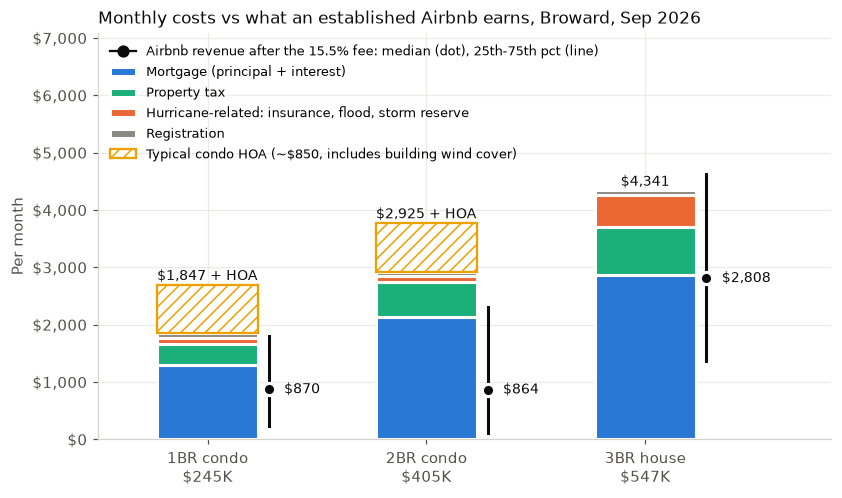

In [7]:
fig, ax = plt.subplots(figsize=(8.6, 4.8))
p50 = monthly[monthly.level == "P50"].set_index("type").loc[TYPE_ORDER]
x = np.arange(len(TYPE_ORDER)); w = 0.46
stack = [("mortgage_mo", "Mortgage (principal + interest)", BLUE),
         ("property_tax_mo", "Property tax", AQUA),
         ("hurricane_mo", "Hurricane-related: insurance, flood, storm reserve", ORANGE),
         ("registration_mo", "Registration", GRAY)]
bottom = np.zeros(len(x))
for col, lab, colr in stack:
    ax.bar(x, p50[col], w, bottom=bottom, color=colr, label=lab, edgecolor="white", linewidth=2)
    bottom += p50[col].values
# Typical condo HOA on top (hatched): Miami-Dade 2025 average $847 (FIU); none assumed for the house
HOA_TYPICAL = 850
for i, t in enumerate(TYPE_ORDER):
    if "condo" in t:
        ax.bar(i, HOA_TYPICAL, w, bottom=bottom[i], facecolor="white", edgecolor=YELLOW, hatch="///",
               linewidth=1.5, label="Typical condo HOA (~$850, includes building wind cover)" if i == 0 else None)
    ax.text(i, bottom[i] + (HOA_TYPICAL if "condo" in t else 0) + 80,
            f"${bottom[i]:,.0f}" + (" + HOA" if "condo" in t else ""), ha="center", color=INK, fontsize=9)
# Net revenue markers
lv = monthly.pivot(index="type", columns="level", values="net_revenue_mo").loc[TYPE_ORDER]
for i, t in enumerate(TYPE_ORDER):
    ax.plot([i + w / 2 + 0.05] * 2, [lv.loc[t, "P25"], lv.loc[t, "P75"]], color=INK, lw=2)
    ax.plot(i + w / 2 + 0.05, lv.loc[t, "P50"], "o", ms=8, color=INK, mec="white", mew=2)
    ax.text(i + w / 2 + 0.12, lv.loc[t, "P50"], f"${lv.loc[t, 'P50']:,.0f}", va="center", fontsize=9, color=INK)
ax.plot([], [], "o-", color=INK, ms=7, label="Airbnb revenue after the 15.5% fee: median (dot), 25th-75th pct (line)")
ax.set_xticks(x, [f"{t}\n${p50.loc[t, 'home_price'] / 1000:,.0f}K" for t in TYPE_ORDER])
ax.yaxis.set_major_formatter(lambda v, _: f"${v:,.0f}")
ax.set_ylabel("Per month")
ax.set_xlim(-0.5, 2.85)
ax.set_title("Monthly costs vs what an established Airbnb earns, Broward, Sep 2026", loc="left", fontsize=11, color=INK)
ax.legend(loc="upper left", frameon=False, fontsize=8.5)
ax.set_ylim(0, max(bottom) + HOA_TYPICAL + 1900)
fig.savefig(FIG / "6_2_costs_vs_revenue.png")
plt.show()

## 6.3 Where the hurricane cost sits, and the HOA you can afford

For a **house**, hurricane risk is on the owner's own bill: wind insurance with the short-term markup, flood insurance and an expected deductible.

For a **condo**, most of it is inside the HOA: the association insures the building against wind and flood and, since the 2022 to 2024 post-Surfside laws, must fully fund structural reserves and pass milestone inspections. Benchmarks for the HOA:

| Benchmark | HOA per month | Source |
|---|---|---|
| Low-rise condo (2 floors or fewer), Miami-Dade 2025 | $440 | [FIU Jorge M. Pérez Metropolitan Center](https://metropolitan.fiu.edu/research/policy-briefings/determinants_of_condominium_association_fees_jpmc_2025.pdf) |
| All condos, Miami-Dade 2025 | $847 | same |
| High-rise (7+ floors), Fort Lauderdale and Palm Beach, 2025 | just over $1,800, of which $438 is the building's insurance | FirstService Residential via [WLRN](https://www.wlrn.org/business/2025-12-05/hoa-condo-costs-florida) |

No public data gives the HOA per building in Broward (data limit), so the answer is a threshold: **only buy if the HOA is under what is left each month.**

In [8]:
hurr = monthly[monthly.level == "P50"].set_index("type")[["costs_mo", "hurricane_mo"]]
hurr["hurricane_share_of_costs"] = hurr.hurricane_mo / hurr.costs_mo
# For condos, add the high-rise HOA's insurance line ($438) to see the full hurricane bill
hurr["with_HOA_insurance_438"] = np.where(hurr.index.str.contains("condo"), hurr.hurricane_mo + 438, hurr.hurricane_mo)
hurr["share_incl_HOA_insurance"] = hurr.with_HOA_insurance_438 / np.where(
    hurr.index.str.contains("condo"), hurr.costs_mo + 438, hurr.costs_mo)
print(hurr.round(2).to_string())

max_hoa = monthly.pivot(index="type", columns="level", values="left_mo").loc[TYPE_ORDER]
max_hoa.columns = [f"max HOA at {c} revenue" for c in max_hoa.columns]
print("\nMonthly amount left for HOA, cleaning, utilities and repairs (negative = no HOA is affordable):")
max_hoa.round(0)

           costs_mo  hurricane_mo  hurricane_share_of_costs  with_HOA_insurance_438  share_incl_HOA_insurance
type                                                                                                         
1BR condo  1,846.77        114.39                      0.06                  552.39                      0.24
2BR condo  2,924.52        114.35                      0.04                  552.35                      0.16
3BR house  4,341.03        569.16                      0.13                  569.16                      0.13

Monthly amount left for HOA, cleaning, utilities and repairs (negative = no HOA is affordable):


,max HOA at P25 revenue,max HOA at P50 revenue,max HOA at P75 revenue
type,,,
1BR condo,"-1,606.00",-977.00,-49.00
2BR condo,"-2,804.00","-2,060.00",-620.00
3BR house,"-2,970.00","-1,533.00",266.00


## 6.4 Break-even occupancy

How many booked nights a year cover the mortgage, tax, insurance and registration (before any HOA), at the median nightly price of established listings of that type? Each storm night lost is already priced into the costs.

In [9]:
be_rows = []
for t in TYPE_ORDER:
    g = est[est.type == t]
    kind, price, nightly = g.kind.iloc[0], g.home_price.median(), g.nightly_price.median()
    fixed = sum(annual_costs(price, kind, 0).values())
    per_night = nightly * (1 - A["fee"]) - nightly / A["hurr_years"] * A["downtime_days"] / 365
    nights_be = fixed / per_night
    row = {"type": t, "median_nightly_price": nightly, "break_even_nights": nights_be,
           "break_even_occupancy": nights_be / 365,
           "median_nights_booked": g.estimated_occupancy_l365d.median(),
           "p75_nights_booked": g.estimated_occupancy_l365d.quantile(0.75),
           "share_at_or_above_break_even": (g.estimated_occupancy_l365d >= nights_be).mean()}
    for hoa in [440, 850]:
        if kind == "condo":
            row[f"break_even_nights_HOA_{hoa}"] = (fixed + hoa * 12) / per_night
    be_rows.append(row)
breakeven = pd.DataFrame(be_rows).set_index("type")
breakeven.round(2)

,median_nightly_price,break_even_nights,break_even_occupancy,median_nights_booked,p75_nights_booked,share_at_or_above_break_even,break_even_nights_HOA_440,break_even_nights_HOA_850
type,,,,,,,,
1BR condo,204.49,128.77,0.35,60.00,132.00,0.25,159.56,188.25
2BR condo,317.45,131.53,0.36,36.00,114.00,0.21,151.37,169.85
3BR house,404.94,152.65,0.42,96.00,168.00,0.29,NaN,NaN


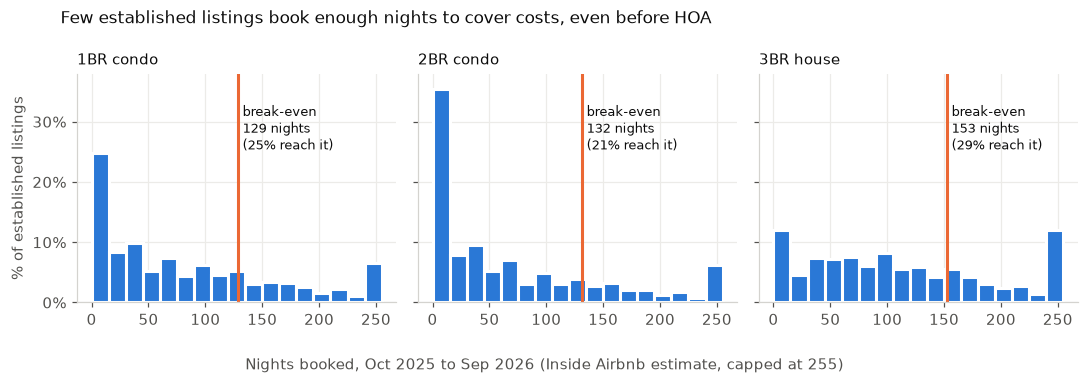

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
bins = np.arange(0, 270, 15)
for ax, t in zip(axes, TYPE_ORDER):
    g = est[est.type == t]
    ax.hist(g.estimated_occupancy_l365d, bins=bins, color=BLUE, edgecolor="white", linewidth=2,
            weights=np.ones(len(g)) / len(g) * 100)
    be = breakeven.loc[t, "break_even_nights"]
    ax.axvline(be, color=ORANGE, lw=2)
    ax.text(be + 4, 33,
            f"break-even\n{be:.0f} nights\n({breakeven.loc[t, 'share_at_or_above_break_even']:.0%} reach it)",
            color=INK, fontsize=8.5, va="top")
    ax.set_title(t, loc="left", fontsize=10, color=INK)
axes[0].set_ylabel("% of established listings")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
for ax in axes:
    ax.set_ylim(0, 38)
fig.supxlabel("Nights booked, Oct 2025 to Sep 2026 (Inside Airbnb estimate, capped at 255)", fontsize=10, color=INK2)
fig.suptitle("Few established listings book enough nights to cover costs, even before HOA", x=0.06, ha="left",
             fontsize=11, color=INK)
fig.tight_layout()
fig.savefig(FIG / "6_4_break_even_nights.png")
plt.show()

## 6.5 Airbnb vs a regular 12-month lease

Same purchase, same mortgage, rented on a 12-month lease at HUD's 2026 Broward rent for that bedroom count, adjusted to the ZIP with Zillow's rent index, with 5% vacancy and an 8% management fee. A landlord pays no short-term markup on insurance and no short-term registration; the tenant pays utilities. The Airbnb owner still has to pay utilities, supplies and furnishing out of "what is left".

In [11]:
lease_rows = []
for t in TYPE_ORDER:
    g = est[est.type == t]
    kind, price, rent = g.kind.iloc[0], g.home_price.median(), g.lease_rent.median()
    lease_net = rent * 12 * (1 - A["vacancy"]) * (1 - A["mgmt"])
    k = annual_costs(price, kind, 0, short_term=False)
    k["storm"] = A["damage_share"] / A["hurr_years"] * (price * A["deductible"] if kind == "house" else 0)
    lease_rows.append({"type": t, "typical_rent_mo": rent, "lease_left_mo": (lease_net - sum(k.values())) / 12,
                       **{f"airbnb_left_mo_{lab}": monthly.query("type == @t and level == @lab").left_mo.iloc[0]
                          for _, lab in LEVELS}})
lease = pd.DataFrame(lease_rows).set_index("type")
lease["airbnb_P75_minus_lease"] = lease.airbnb_left_mo_P75 - lease.lease_left_mo
lease.round(0)

,typical_rent_mo,lease_left_mo,airbnb_left_mo_P25,airbnb_left_mo_P50,airbnb_left_mo_P75,airbnb_P75_minus_lease
type,,,,,,
1BR condo,"2,017.00",18.00,"-1,606.00",-977.00,-49.00,-67.00
2BR condo,"2,496.00",-641.00,"-2,804.00","-2,060.00",-620.00,21.00
3BR house,"3,207.00","-1,365.00","-2,970.00","-1,533.00",266.00,"1,632.00"


## 6.6 The newcomer's odds

The numbers above describe survivors. A newcomer is more like the listings that were new in **December 2025**: first-year listings (first review in the year before) and listings with no reviews yet, of the same three types. Where were they nine months later, in September 2026?

- **gone:** not in the September scrape (left Airbnb, or moved to a long-term lease)
- **still zero:** listed, but no review in the past 12 months (no estimated bookings)
- **earning:** listed with at least one estimated booking

In [12]:
dec = listings[(listings.snapshot_date == DEC) & (listings.room_type == "Entire home/apt") & (listings.mid_term == 0)]
sep_all = listings[listings.snapshot_date == SEP].set_index("id")
GROUPS = ["no reviews yet", "first year", "established (1+ year)"]
odds = []
for t, (br, ptypes, col, kind) in TYPES.items():
    for grp in GROUPS:
        ids = dec[(dec.bedrooms == br) & dec.property_type.isin(ptypes) & (dec.listing_age_group == grp)].id
        later = sep_all.loc[ids[ids.isin(sep_all.index)]]
        rev = later.loc[later.analysis_ready == 1, "estimated_revenue_l365d"]
        odds.append({"type": t, "group_in_dec": grp, "listings": len(ids),
                     "gone": 1 - len(later) / len(ids),
                     "still_zero": (later.estimated_occupancy_l365d == 0).sum() / len(ids),
                     "earning": (later.estimated_occupancy_l365d > 0).sum() / len(ids),
                     "survivor_revenue_median": rev.median() * SEASON[t]})
odds = pd.DataFrame(odds)
pooled = odds.assign(g=odds.gone * odds.listings, z=odds.still_zero * odds.listings, e=odds.earning * odds.listings
                     ).groupby("group_in_dec")[["listings", "g", "z", "e"]].sum().loc[GROUPS]
pooled[["gone", "still_zero", "earning"]] = pooled[["g", "z", "e"]].div(pooled.listings, axis=0)
pooled = pooled[["listings", "gone", "still_zero", "earning"]]
print("All three types pooled:")
print(pooled.round(3).to_string())
odds.round(3)

All three types pooled:
                       listings  gone  still_zero  earning
group_in_dec                                              
no reviews yet             1198  0.35        0.41     0.24
first year                 1706  0.34        0.06     0.59
established (1+ year)      5322  0.20        0.15     0.64


,type,group_in_dec,listings,gone,still_zero,earning,survivor_revenue_median
0,1BR condo,no reviews yet,593,0.34,0.42,0.23,0.00
1,1BR condo,first year,806,0.36,0.06,0.58,"14,810.04"
2,1BR condo,established (1+ year),2473,0.22,0.14,0.64,"12,616.21"
3,2BR condo,no reviews yet,458,0.33,0.45,0.22,0.00
4,2BR condo,first year,483,0.31,0.10,0.59,"24,565.88"
5,2BR condo,established (1+ year),1634,0.17,0.22,0.61,"12,252.28"
6,3BR house,no reviews yet,147,0.41,0.28,0.31,"4,811.88"
7,3BR house,first year,417,0.34,0.02,0.63,"53,044.69"
8,3BR house,established (1+ year),1215,0.22,0.08,0.69,"38,743.62"


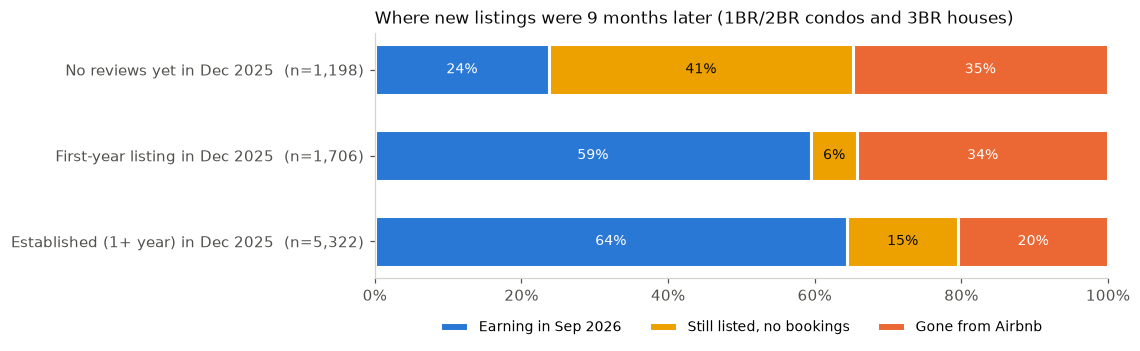

In [13]:
fig, ax = plt.subplots(figsize=(8.6, 2.9))
labels = {"no reviews yet": "No reviews yet in Dec 2025", "first year": "First-year listing in Dec 2025",
          "established (1+ year)": "Established (1+ year) in Dec 2025"}
segs = [("earning", "Earning in Sep 2026", BLUE), ("still_zero", "Still listed, no bookings", YELLOW),
        ("gone", "Gone from Airbnb", ORANGE)]
y = np.arange(len(GROUPS))[::-1]
left = np.zeros(len(GROUPS))
for col, lab, colr in segs:
    vals = pooled[col].values * 100
    ax.barh(y, vals, left=left, color=colr, edgecolor="white", linewidth=2, height=0.6, label=lab)
    for yi, l, v in zip(y, left, vals):
        if v >= 6:
            ax.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if col != "still_zero" else INK)
    left += vals
ax.set_yticks(y, [f"{labels[g]}  (n={pooled.loc[g, 'listings']:,})" for g in GROUPS])
ax.set_xlim(0, 100); ax.grid(False)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False, fontsize=9)
ax.set_title("Where new listings were 9 months later (1BR/2BR condos and 3BR houses)", loc="left", fontsize=11, color=INK)
fig.savefig(FIG / "6_6_newcomer_odds.png")
plt.show()

## 6.7 Hurricane season is also the slow season

Guests review about two weeks after checkout, so reviews per month trace stays with a short lag. Each year is scaled to its own monthly average (100) so growth in the market does not hide the pattern; 2023 to 2025 are the complete years (September 2026 is partial). Hurricane season runs June 1 to November 30 and peaks in mid-September.

In [14]:
rv = pd.read_parquet(DATA / "reviews.parquet", columns=["date"])
rv = rv[(rv.date >= "2023-01-01") & (rv.date < "2026-01-01")]
per_month = rv.groupby([rv.date.dt.year.rename("year"), rv.date.dt.month.rename("month")]).size().rename("reviews").reset_index()
per_month["index"] = per_month.reviews / per_month.groupby("year").reviews.transform("mean") * 100
season = per_month.pivot(index="month", columns="year", values="index")
season["average"] = season.mean(axis=1)
hurricane_months = [6, 7, 8, 9, 10, 11]
print(f"Average index, hurricane season (Jun-Nov): {season.loc[hurricane_months, 'average'].mean():.0f}; "
      f"rest of year (Dec-May): {season.loc[~season.index.isin(hurricane_months), 'average'].mean():.0f}")
season.round(0)

Average index, hurricane season (Jun-Nov): 90; rest of year (Dec-May): 110


year,2023,2024,2025,average
month,,,,
1,103.00,97.00,99.00,100.00
2,101.00,99.00,100.00,100.00
3,133.00,130.00,129.00,131.00
4,117.00,110.00,111.00,113.00
5,106.00,103.00,102.00,104.00
6,83.00,90.00,97.00,90.00
7,102.00,100.00,97.00,100.00
8,86.00,83.00,91.00,86.00
9,70.00,77.00,74.00,74.00


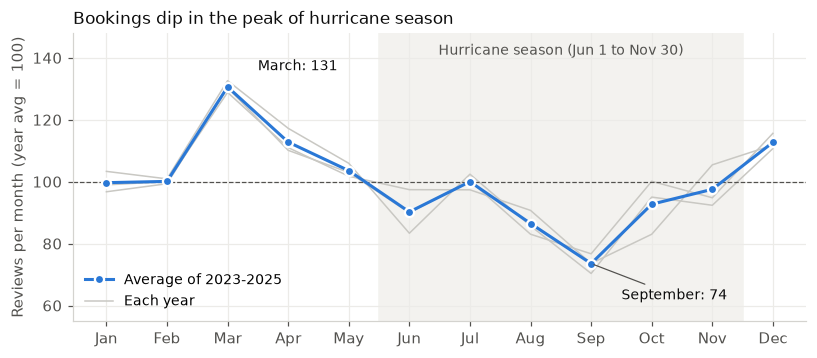

In [15]:
fig, ax = plt.subplots(figsize=(8.6, 3.4))
ax.axvspan(5.5, 11.5, color="#f3f2ef", zorder=0)
ax.text(8.5, 141, "Hurricane season (Jun 1 to Nov 30)", ha="center", color=INK2, fontsize=9)
for yr in [2023, 2024, 2025]:
    ax.plot(season.index, season[yr], color="#c9c8c3", lw=1, zorder=1)
ax.plot(season.index, season.average, color=BLUE, lw=2, marker="o", ms=6, mec="white", mew=1.5, zorder=3,
        label="Average of 2023-2025")
ax.plot([], [], color="#c9c8c3", lw=1, label="Each year")
ax.axhline(100, color=INK2, lw=0.8, ls="--")
lo = season.average.idxmin()
ax.annotate(f"September: {season.average.min():.0f}", (lo, season.average.min()), xytext=(lo + 0.5, 62),
            fontsize=9, color=INK, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
hi = season.average.idxmax()
ax.annotate(f"March: {season.average.max():.0f}", (hi, season.average.max()), xytext=(hi + 0.5, 136),
            fontsize=9, color=INK)
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylim(55, 148)
ax.set_ylabel("Reviews per month (year avg = 100)")
ax.legend(loc="lower left", frameon=False, fontsize=9)
ax.set_title("Bookings dip in the peak of hurricane season", loc="left", fontsize=11, color=INK)
fig.savefig(FIG / "6_7_hurricane_season.png")
plt.show()

## 6.8 What would make it work?

**Sensitivity.** Median established revenue, one assumption changed at a time, monthly amount left before HOA.

In [16]:
def left_at(t, a=A, rate=RATE, mult=1.0, ins_mult=1.0, season=None):
    g = est[est.type == t]
    kind, price = g.kind.iloc[0], g.home_price.median()
    factor = SEASON[t] if season is None else season[t]
    rev = g.estimated_revenue_l365d.median() * factor * mult
    aa = dict(a); aa["ho6"] *= ins_mult; aa["home_ins_per_1000"] *= ins_mult
    return (rev * (1 - aa["fee"]) - sum(annual_costs(price, kind, rev, a=aa, rate=rate).values())) / 12

scen = {
    "Base case": {},
    "September prices only (no full-year adjustment)": {"season": pd.Series(1.0, index=TYPE_ORDER)},
    "Full-year prices from March and September only": {"season": SEASON_MAR_SEP},
    "Mortgage rate 6.0%": {"rate": 0.060},
    "25% down": {"a": {**A, "down": 0.25}},
    "No short-term insurance markup": {"a": {**A, "str_markup": 0.0}},
    "Insurance +50% (post-storm repricing)": {"ins_mult": 1.5},
    "Hurricane every 4 years, 5% deductible": {"a": {**A, "hurr_years": 4, "deductible": 0.05}},
    "Bookings 1.5x the review-based estimate": {"mult": 1.5},
    "Bookings 2x the review-based estimate": {"mult": 2.0},
    "Bought in cash (no mortgage)": {"a": {**A, "down": 1.0}},
}
sens = pd.DataFrame({name: {t: left_at(t, **kw) for t in TYPE_ORDER} for name, kw in scen.items()}).T
sens.round(0)

,1BR condo,2BR condo,3BR house
Base case,-977.00,"-2,060.00","-1,533.00"
September prices only (no full-year adjustment),"-1,063.00","-2,162.00","-1,803.00"
Full-year prices from March and September only,-989.00,"-2,082.00","-1,585.00"
Mortgage rate 6.0%,-866.00,"-1,877.00","-1,285.00"
25% down,-896.00,"-1,927.00","-1,353.00"
No short-term insurance markup,-955.00,"-2,039.00","-1,454.00"
Insurance +50% (post-storm repricing),"-1,031.00","-2,114.00","-1,729.00"
"Hurricane every 4 years, 5% deductible",-980.00,"-2,063.00","-1,752.00"
Bookings 1.5x the review-based estimate,-545.00,"-1,631.00",-139.00
Bookings 2x the review-based estimate,-113.00,"-1,202.00","1,255.00"


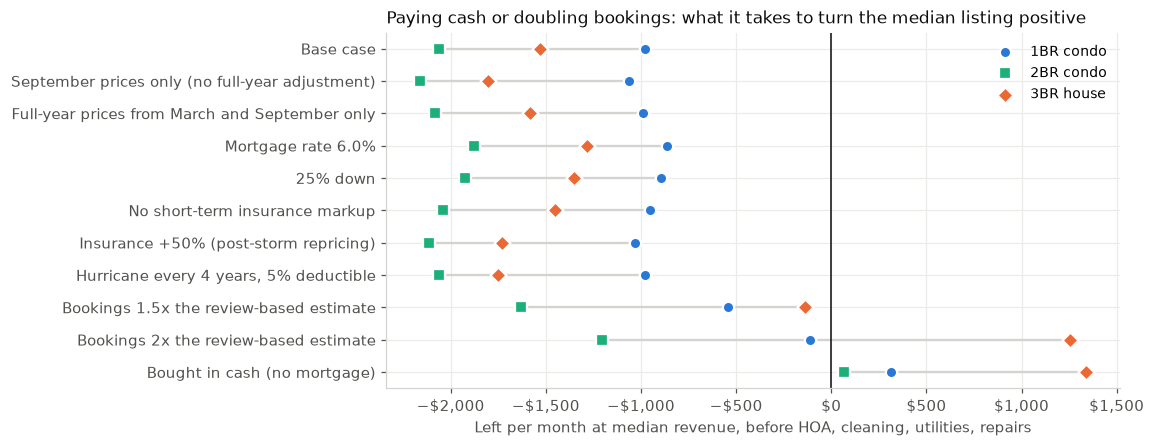

In [17]:
fig, ax = plt.subplots(figsize=(8.6, 4.2))
yy = np.arange(len(sens))[::-1]
for (t, colr, mk) in zip(TYPE_ORDER, [BLUE, AQUA, ORANGE], ["o", "s", "D"]):
    ax.scatter(sens[t], yy, color=colr, marker=mk, s=55, edgecolor="white", linewidth=1.5, zorder=3, label=t)
for yi, (_, r) in zip(yy, sens.iterrows()):
    ax.plot([r.min(), r.max()], [yi, yi], color="#d4d3cf", lw=1.5, zorder=1)
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(yy, sens.index)
ax.xaxis.set_major_formatter(lambda v, _: f"−${-v:,.0f}" if v < 0 else f"${v:,.0f}")
ax.set_xlabel("Left per month at median revenue, before HOA, cleaning, utilities, repairs")
ax.legend(loc="upper right", frameon=False, fontsize=9)
ax.set_title("Paying cash or doubling bookings: what it takes to turn the median listing positive", loc="left", fontsize=11, color=INK)
fig.savefig(FIG / "6_8_sensitivity.png")
plt.show()

**Maximum purchase price.** Costs rise in a straight line with the price, so we can solve for the price at which revenue just covers the costs plus an HOA (condos: the $440 low-rise benchmark; house: none).

In [18]:
mp = []
for t in TYPE_ORDER:
    g = est[est.type == t]
    kind, hoa = g.kind.iloc[0], (440 if "condo" in t else 0)
    row = {"type": t, "typical_price": g.home_price.median(), "HOA_assumed_mo": hoa}
    for q, lab in LEVELS:
        rev = g.revenue_yr.quantile(q)
        c0 = sum(annual_costs(0, kind, rev).values()); c1 = sum(annual_costs(1, kind, rev).values()) - c0
        row[f"max_price_at_{lab}"] = max(0, (rev * (1 - A["fee"]) - c0 - hoa * 12) / c1)
    mp.append(row)
max_price = pd.DataFrame(mp).set_index("type")
max_price["P75_max_as_share_of_typical"] = max_price.max_price_at_P75 / max_price.typical_price
max_price.round(2)

,typical_price,HOA_assumed_mo,max_price_at_P25,max_price_at_P50,max_price_at_P75,P75_max_as_share_of_typical
type,,,,,,
1BR condo,"245,471.04",440,0.00,"35,846.47","173,135.02",0.71
2BR condo,"404,938.97",440,0.00,"35,012.91","248,044.12",0.61
3BR house,"547,232.47",0,"157,321.87","346,011.67","582,206.71",1.06


## Findings for the report

Snapshot September 2026, `analysis_ready`, whole homes; prices are Zillow September 2026 by ZIP; rate 6.86%, 20% down. Revenue is scaled from September prices to a full-year price level (x1.11 to x1.14, see 6.2). Every figure below is printed by a cell above.

1. **For a typical buyer, it does not pay.** At the median revenue of established listings, a 1BR condo is short by about $980 a month, a 2BR condo by about $2,060 and a 3BR house by about $1,530, **before** HOA, cleaning, utilities or repairs. Only about 1 in 4 established listings (22% to 25% by type) covers these costs, even paired with its own ZIP's price. Using September prices without the full-year adjustment would make each shortfall $85 to $270 a month worse.
2. **The HOA threshold is negative for condos.** "Only buy if the HOA is under $X": X is below zero even at the 75th percentile of revenue (1BR about -$50, 2BR about -$620), while Broward condo HOAs run $440 (low-rise) to $1,800+ (beach high-rises). Only about 17% to 18% of established condo listings leave more than $440 a month, the low-rise HOA benchmark, so a condo works only for a top performer in a low-fee building.
3. **Where hurricanes enter.** For a house, insurance, flood cover and the storm reserve are about $570 a month, 13% of costs. For a condo, the owner's own policy is small, but the HOA carries the building's wind and flood insurance ($438 a month in Fort Lauderdale high-rises) plus post-Surfside reserves. Adding that one line, 16% (2BR) to 24% (1BR) of a condo owner's costs are hurricane-driven, before counting the reserves. A post-storm 50% insurance jump costs a house owner another $200 a month.
4. **Break-even is 129 to 153 booked nights a year** (35% to 42%) before HOA, and 151 to 160 for a condo with a $440 HOA. Established listings book a median of 36 to 96 nights; only 21% to 29% reach break-even.
5. **The newcomer's odds are worse than the survivors'.** Of the December 2025 no-review listings of these types, about a third were gone nine months later and about 4 in 10 were still listed with no bookings; only about 1 in 4 was earning. First-year listings did better (about 6 in 10 earning) but a third of them had also left. The first-year listings that stayed earned as much as or more than established ones, which is the survivorship effect: the ones that would have dragged the average down are the ones that left.
6. **Hurricane season is the slow season.** Reviews (a stand-in for stays) run about 10% below average from June to November, and September, the peak of hurricane season, is the weakest month (about 26% below average). The storm risk and the low revenue arrive together.
7. **For a condo, a plain 12-month lease does as well as a top Airbnb.** At HUD's Broward rents, a 1BR condo on a lease about breaks even before HOA (+$20 a month), a 2BR loses about $640 and a 3BR house about $1,370. A median Airbnb does worse than the lease for all three types. A top-quartile Airbnb only matches the lease for condos (1BR about $70 worse, 2BR about $20 better), but beats it by about $1,630 a month for the house, before the Airbnb's extra utilities, supplies and furnishing. So the house is the one type where running an Airbnb well pays off over renting it out.
8. **What would make it work:** paying cash (before HOA: the house leaves about +$1,340 a month, the 1BR condo +$310 and the 2BR condo +$65), or real bookings about twice the review-based estimate (the house turns positive at +$1,250; the condos do not). A lower rate or 25% down barely helps (+$80 to +$250 a month). At 75th-percentile revenue with a $440 HOA, a condo pays for itself only if bought at 61% (2BR) to 71% (1BR) of Zillow's typical price; a house at 75th-percentile revenue covers its costs at the typical price (up to about 106% of it).

**Recommendation for the client:** do not buy a Broward condo to Airbnb with a mortgage in 2026: even a top-quartile condo listing does no better than a plain 12-month lease, and neither covers a real HOA. A 3BR house is the only type that can work, and only for someone who can credibly run a top-quartile listing or put far more down. For condos, get the building's HOA budget, insurance line and reserve study before anything else; a high-rise beach HOA alone exceeds what a median listing earns. Budget for the September slump and keep cash for one hurricane deductible (2% of value, $11K on a $547K house).

## Limits (for the "additional data" section)

- **Revenue is an estimate** from reviews (half of guests assumed to review, 255-night cap), priced from three scrape days rather than actual nightly rates. If fewer guests review, real revenue is higher; 6.8 shows that even 2x bookings leave the median condo short.
- **No HOA per building**, and no insurance quote per property; insurance figures are county or state averages from 2026 sources.
- **No flood zone per property.** The flood premium is the Broward average; AE and VE beach zones cost much more, condo unit owners in high-risk zones may also need it.
- Hurricane frequency, deductible share and downtime are assumptions (tested in 6.8). A direct hit could cost far more than the average reserve.
- Long-term rent is HUD's county rent by bedroom count (40th percentile) adjusted by the ZIP's Zillow rent, not a quote for a specific unit.
- Survivors: "gone" listings may have switched to a long-term lease or sold rather than failed.

## Export for the dashboard

The inputs behind 6.2 to 6.8, so the dashboard's calculator uses the same numbers and cost rules as this notebook (`annual_costs`).

In [19]:
import json
QS = [0.1, 0.25, 0.5, 0.75, 0.9]
types = {}
for t in TYPE_ORDER:
    g = est[est.type == t]
    types[t] = {"kind": g.kind.iloc[0], "listings": int(len(g)), "home_price": float(g.home_price.median()),
                "season_factor": float(SEASON[t]), "nightly_price": float(g.nightly_price.median()),
                "median_nights": float(g.estimated_occupancy_l365d.median()),
                "revenue": {str(q): float(g.revenue_yr.quantile(q)) for q in QS},
                "lease_rent": float(g.lease_rent.median()),
                "share_covering_costs": float(cover.loc[t, "share_positive"]),
                "break_even_nights": float(breakeven.loc[t, "break_even_nights"])}
export = {"rate": float(RATE), "assumptions": {k: float(v) for k, v in A.items()}, "hud_fmr": HUD_FMR,
          "types": types,
          "newcomer_odds": pooled.reset_index().rename(columns={"group_in_dec": "group"}).round(4).to_dict("records"),
          "season_index": season.average.round(1).to_dict(),
          "sensitivity": sens.round(0).reset_index().rename(columns={"index": "scenario"}).to_dict("records")}
(FIG / "dashboard_model.json").write_text(json.dumps(export, indent=1))
print("wrote", FIG / "dashboard_model.json")

wrote figures/ch6/dashboard_model.json
